# Ice-shelf flexure from meltwater lakes: using the model, testing it, going 2-D, and going fast

This notebook is a hands-on companion to [`derivation.md`](derivation.md) / [`derivation.pdf`](derivation.pdf).

1. **Using the 1-D model.** Lakes appearing, filling and draining, grounding lines, variable thickness, and water moving between lakes.
2. **Verification.** Every test listed in §12 of the derivation, with plots and numbers.
3. **Two horizontal dimensions.** The viscoelastic *plate* model in [`viscoelastic_plate.py`](viscoelastic_plate.py): equations, two solvers, verification, a circular lake, and a real lake map from this repository's fill-spill-merge output.
4. **Computation time.** Where the time goes, faster implementations, scaling with grid size, run-time estimates, and recommendations.

All the code lives in this folder: `viscoelastic_beam.py` (1-D), `viscoelastic_plate.py` (2-D), `fast_beam.py` (fast 1-D loops) and `tests/`. The notebook only *uses* it.

Run it from the `flexure` folder. It needs `numpy scipy matplotlib pandas`, plus optionally `numba` (fast 1-D loop) and `tifffile` (real lake map). Executing the whole notebook takes a few minutes, most of it in the benchmarks of Part 4. All timings are wall-clock times on the machine printed below, so expect yours to differ.

In [1]:
import os, platform, subprocess, sys, time
import numpy as np, scipy, matplotlib, matplotlib.pyplot as plt, pandas as pd

import plotstyle as ps
from viscoelastic_beam import (IceShelf, ViscoelasticBeam, SECONDS_PER_DAY as DAY,
                               parabolic_lake, fill_hold_drain, relaxation_time,
                               spectral_step_response, hetenyi_strip, grounding_line_profile)
from viscoelastic_plate import SpectralPlate, FDPlate, point_load_plate, principal_stresses
import fast_beam

ps.apply()
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100})
pd.set_option("display.precision", 3)

def best_time(fn, repeat=3):
    "Best-of-`repeat` wall-clock time of fn() in seconds."
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

print(f"python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, "
      f"numba {'yes' if fast_beam.HAVE_NUMBA else 'not installed'}")
print(f"{platform.machine()}, {os.cpu_count()} logical CPUs, {platform.system()}")

python 3.13.18, numpy 2.5.3, scipy 1.18.1, numba yes
x86_64, 4 logical CPUs, Linux


---
## 1. Using the 1-D model

### 1.1 Parameters

`IceShelf` holds the material parameters. Everything is in SI units, and the derived quantities are properties. Two numbers control the behaviour:

* the **flexural length** $\ell=(D/k)^{1/4}$, which sets the horizontal scale of bending;
* the **Maxwell time** $\tau = 4\eta(1-\nu^2)/E$, which sets the time scale of creep.

Ice is elastic with Poisson's ratio `nu` = 0.3, but it creeps without changing volume, so the viscous part has `nu_v` = 0.5. The bending moment therefore has two parts (isotropic and deviatoric) with relaxation times `shelf.taus`, about 4.9 and 3.0 days, whose rigidity-weighted mean is $\tau$ (§5 of the derivation). `IceShelf(nu_v=0.3)` gives the simpler single-time model.

In [2]:
shelf = IceShelf()            # H = 250 m, E = 1 GPa, nu = 0.3, nu_v = 0.5, eta = 1e14 Pa s
print(f"D   = {shelf.D:.3e} N m      (flexural rigidity)")
print(f"k   = {shelf.k:.0f} Pa/m       (buoyancy stiffness)")
print(f"ell = {shelf.ell:.0f} m            (flexural length)")
print(f"tau = {shelf.tau/DAY:.2f} days        (mean Maxwell time)")
print(f"tau_1, tau_2 = {shelf.taus[0]/DAY:.2f}, {shelf.taus[1]/DAY:.2f} days   (isotropic and deviatoric parts)")

# how they change with thickness, stiffness and viscosity
rows = []
for H in (100, 250, 500):
    for E in (1e9, 9e9):
        for eta in (1e13, 1e14, 1e15):
            s = IceShelf(H=H, E=E, eta=eta)
            rows.append(dict(H_m=H, E_GPa=E/1e9, eta=f"{eta:.0e}", ell_m=round(float(s.ell)),
                             tau_days=float(s.tau)/DAY))
pd.DataFrame(rows).pivot_table(index=["H_m", "E_GPa"], columns="eta", values=["ell_m", "tau_days"])

D   = 1.431e+15 N m      (flexural rigidity)
k   = 10085 Pa/m       (buoyancy stiffness)
ell = 614 m            (flexural length)
tau = 4.21 days        (mean Maxwell time)
tau_1, tau_2 = 4.86, 3.01 days   (isotropic and deviatoric parts)


ell_m                 tau_days               
eta         1e+13   1e+14   1e+15    1e+13  1e+14   1e+15
H_m E_GPa                                                
100 1.0     309.0   309.0   309.0    0.421  4.213  42.130
    9.0     535.0   535.0   535.0    0.047  0.468   4.681
250 1.0     614.0   614.0   614.0    0.421  4.213  42.130
    9.0    1063.0  1063.0  1063.0    0.047  0.468   4.681
500 1.0    1032.0  1032.0  1032.0    0.421  4.213  42.130
    9.0    1788.0  1788.0  1788.0    0.047  0.468   4.681

### 1.2 A lake that appears and stays

The workflow has three steps:

1. Make a grid `x` (equally spaced, in metres) and a `ViscoelasticBeam`.
2. Describe the load. Here it is a function `q(t)` returning pascals on the grid; `shelf.lake_load(depth)` converts water depth to load.
3. Call `run(t, load)`.

The result has `w` (deflection, positive down), `M` (bending moment) and `sigma` (upper-surface stress, positive = tension), each of shape `(len(t), len(x))`.

3001 nodes x 1201 steps: 1.09 s


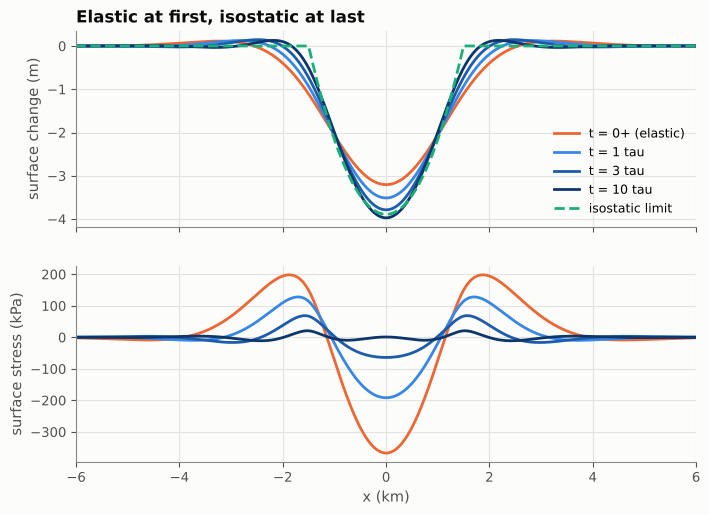

In [3]:
x = np.linspace(-15e3, 15e3, 3001)                       # 10 m spacing
beam = ViscoelasticBeam(x, shelf)                        # free ends far away
depth = parabolic_lake(x, centre=0, half_width=1500, max_depth=4.0)
q = shelf.lake_load(depth)

t = np.linspace(0, 30 * shelf.tau, 1201)
t0 = time.perf_counter()
res = beam.run(t, lambda tt: q)                          # lake present from t = 0
print(f"{x.size} nodes x {t.size} steps: {time.perf_counter() - t0:.2f} s")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
for s, c in zip([0, 1, 3, 10], [ps.ELASTIC, ps.SEQ[3], ps.SEQ[6], ps.SEQ[9]]):
    i = np.argmin(abs(t - s * shelf.tau))
    lab = "t = 0+ (elastic)" if s == 0 else f"t = {s} tau"
    a1.plot(x/1e3, -res.w[i], color=c, label=lab); a2.plot(x/1e3, res.sigma[i]/1e3, color=c)
a1.plot(x/1e3, -beam.isostatic(q), "--", color=ps.ISO, label="isostatic limit")
a1.set_ylabel("surface change (m)"); a1.legend(loc="lower right", fontsize=9)
a2.set_ylabel("surface stress (kPa)"); a2.set_xlabel("x (km)"); a1.set_xlim(-6, 6)
a1.set_title("Elastic at first, isostatic at last"); plt.show()

### 1.3 Any load history

The load can be any function of time, or an array of shape `(nt, nx)`. `fill_hold_drain` is a helper for the classic cycle. Because the model is linear, the stress *reverses* when a lake that has relaxed drains quickly.

function vs array load, max difference: 0.0 m


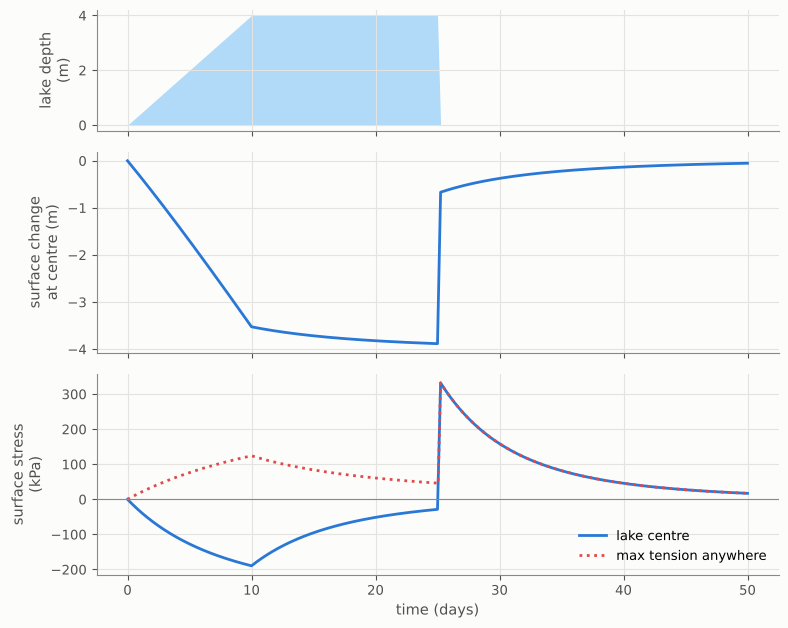

In [4]:
t = np.linspace(0, 50 * DAY, 1001)
history = lambda tt: fill_hold_drain(tt, t_fill=10*DAY, t_hold=15*DAY, t_drain=0.25*DAY)
res = beam.run(t, lambda tt: q * history(tt))

# the same run with the load given as an array
res_arr = beam.run(t, q[None, :] * history(t)[:, None])
print("function vs array load, max difference:", np.abs(res.w - res_arr.w).max(), "m")

i0 = np.argmin(abs(x))
fig, ax = plt.subplots(3, 1, figsize=(8, 6.4), sharex=True, gridspec_kw=dict(height_ratios=[0.6, 1, 1]))
ax[0].fill_between(t/DAY, 4 * history(t), color=ps.WATER, alpha=0.4, lw=0); ax[0].set_ylabel("lake depth\n(m)")
ax[1].plot(t/DAY, -res.w[:, i0], color=ps.VISCO); ax[1].set_ylabel("surface change\nat centre (m)")
ax[2].plot(t/DAY, res.sigma[:, i0]/1e3, color=ps.VISCO, label="lake centre")
ax[2].plot(t/DAY, res.sigma.max(axis=1)/1e3, ":", color=ps.TENSION, label="max tension anywhere")
ax[2].axhline(0, color=ps.MUTED, lw=0.8); ax[2].legend(loc="lower right"); ax[2].set_ylabel("surface stress\n(kPa)")
ax[2].set_xlabel("time (days)"); fig.tight_layout(); plt.show()

### 1.4 Grounding lines and a thinning shelf

`left='clamped'` models a grounding line, where $w = w' = 0$. `right='free'` models a calving front. `H` may be an array, which gives a shelf that thins seawards. Both $D$ and $\Lambda$ scale as $H^3$, so $\tau$ does not change, but $\ell \propto H^{3/4}$ does.

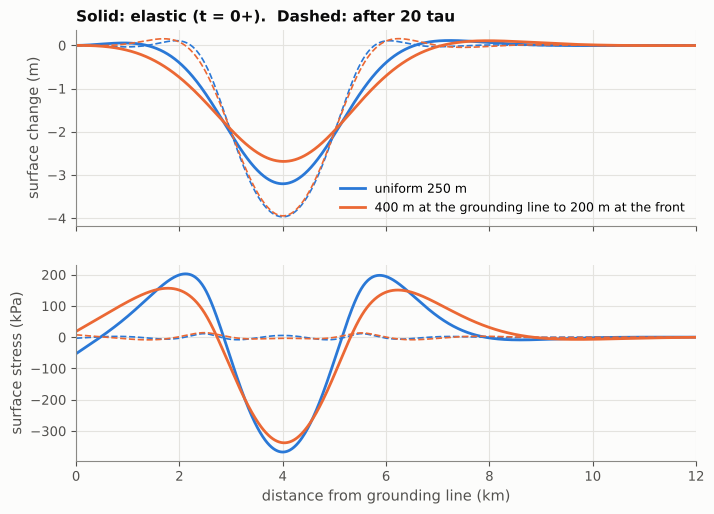

In [5]:
x = np.linspace(0, 30e3, 3001)
depth = parabolic_lake(x, centre=4e3, half_width=1500, max_depth=4.0)
t = np.linspace(0, 20 * shelf.tau, 401)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
for H, c, lab in [(250.0, ps.VISCO, "uniform 250 m"),
                  (np.linspace(400, 200, x.size), ps.ELASTIC, "400 m at the grounding line to 200 m at the front")]:
    s = IceShelf(H=H)
    r = ViscoelasticBeam(x, s, left="clamped", right="free").run(t, lambda tt: s.lake_load(depth))
    a1.plot(x/1e3, -r.w[0], color=c, label=lab); a1.plot(x/1e3, -r.w[-1], "--", color=c, lw=1.2)
    a2.plot(x/1e3, r.sigma[0]/1e3, color=c); a2.plot(x/1e3, r.sigma[-1]/1e3, "--", color=c, lw=1.2)
a1.legend(fontsize=9, loc="lower right"); a1.set_ylabel("surface change (m)")
a1.set_title("Solid: elastic (t = 0+).  Dashed: after 20 tau", fontsize=11)
a2.set_ylabel("surface stress (kPa)"); a2.set_xlabel("distance from grounding line (km)"); a1.set_xlim(0, 12)
plt.show()

### 1.5 Water moving from one lake to another

This is the situation the wider BFRN project is about: melt is produced in one place and ends up somewhere else. Lake A fills over 10 days. On day 15 it drains over one day into lake B, which is wider and shallower, and the volume is conserved. The load is passed as an array.

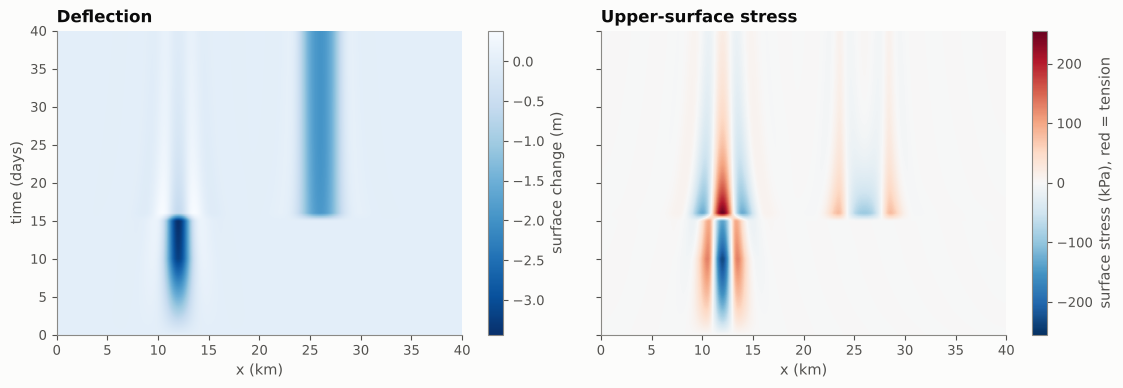

water volume check: A 6399.6, B 6399.6 m^2 per metre of shelf


In [6]:
x = np.linspace(0, 40e3, 2001)
beam2 = ViscoelasticBeam(x, shelf)
dA = parabolic_lake(x, 12e3, 1200, 4.0)
dB = parabolic_lake(x, 26e3, 2400, 1.0)
dB *= np.trapezoid(dA, x) / np.trapezoid(dB, x)        # same water volume
t = np.linspace(0, 40 * DAY, 801)
fill = np.clip(t / (10 * DAY), 0, 1)
move = np.clip((t - 15 * DAY) / DAY, 0, 1)              # fraction transferred to B
depths = (fill * (1 - move))[:, None] * dA + (fill * move)[:, None] * dB
res = beam2.run(t, shelf.lake_load(depths))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
im = ax[0].pcolormesh(x/1e3, t/DAY, -res.w, cmap="Blues_r", shading="auto")
fig.colorbar(im, ax=ax[0], label="surface change (m)")
lim = np.abs(res.sigma).max() / 1e3
im = ax[1].pcolormesh(x/1e3, t/DAY, res.sigma/1e3, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
fig.colorbar(im, ax=ax[1], label="surface stress (kPa), red = tension")
ax[0].set_ylabel("time (days)")
for a, ttl in zip(ax, ["Deflection", "Upper-surface stress"]):
    a.set_xlabel("x (km)"); a.set_title(ttl); a.grid(False)
fig.tight_layout(); plt.show()
print(f"water volume check: A {np.trapezoid(dA, x):.1f}, B {np.trapezoid(dB, x):.1f} m^2 per metre of shelf")

---
## 2. Verification: the tests from §12 of the derivation

Each test compares the model with an exact solution. The numbers are collected into a table at the end of this part, and the same checks run automatically in `tests/test_viscoelastic_beam.py` (the last cell of this part runs them).

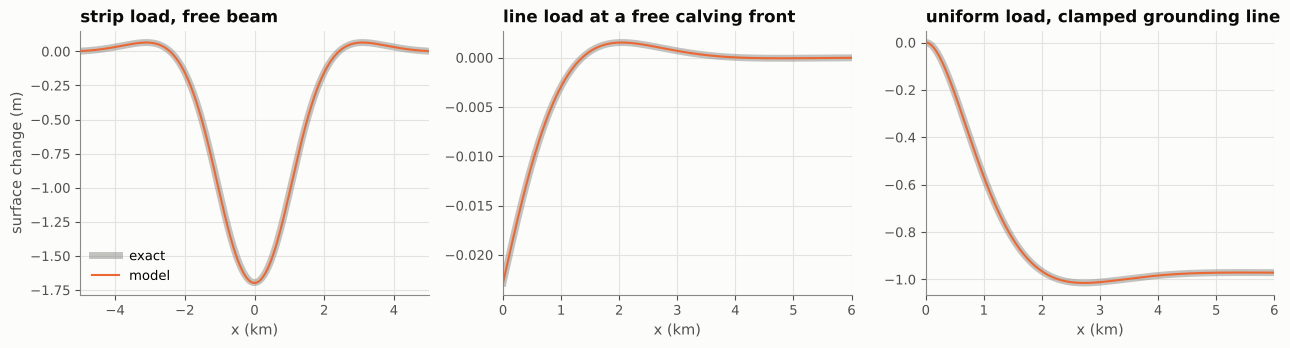

,test,error,tolerance,passed
0,elastic strip load (Hetényi),1.676e-03,0.002,True
1,line load at a free front,8.203e-06,0.002,True
2,"uniform load, clamped grounding line",6.526e-06,0.001,True


In [7]:
checks = []   # (test, measured error, tolerance used in the test-suite)
def record(name, err, tol):
    checks.append(dict(test=name, error=err, tolerance=tol, passed=bool(err < tol)))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))

# 2.1 elastic strip load on a long free beam vs Hetenyi (1946)
x = np.linspace(-20e3, 20e3, 8001); a, q0 = 1000.0, shelf.lake_load(2.0)
w, _ = ViscoelasticBeam(x, shelf).elastic(np.where(abs(x) <= a, q0, 0.0))
ex = hetenyi_strip(x, a, q0, shelf)
record("elastic strip load (Hetényi)", np.abs(w - ex).max() / ex.max(), 2e-3)
ax[0].plot(x/1e3, -ex, color=ps.MUTED, lw=5, alpha=.5, label="exact"); ax[0].plot(x/1e3, -w, color=ps.ELASTIC, lw=1.5, label="model")
ax[0].set_xlim(-5, 5); ax[0].set_title("strip load, free beam"); ax[0].legend()

# 2.2 line load P at a free calving front: w = (2 P beta / k) exp(-beta x) cos(beta x)
x = np.linspace(0, 20e3, 4001); dx = x[1] - x[0]; P = 1e5
qq = np.zeros_like(x); qq[0] = P / (0.5 * dx)              # end node carries half a cell
w, _ = ViscoelasticBeam(x, shelf).elastic(qq)
beta = (shelf.k / (4 * shelf.D)) ** 0.25
ex = 2 * P * beta / shelf.k * np.exp(-beta * x) * np.cos(beta * x)
record("line load at a free front", np.abs(w - ex).max() / ex.max(), 2e-3)
ax[1].plot(x/1e3, -ex, color=ps.MUTED, lw=5, alpha=.5); ax[1].plot(x/1e3, -w, color=ps.ELASTIC, lw=1.5)
ax[1].set_xlim(0, 6); ax[1].set_title("line load at a free calving front")

# 2.3 uniform load on a beam clamped at a grounding line: the tidal-flexure profile
x = np.linspace(0, 20e3, 4001); q0 = shelf.lake_load(1.0)
w, _ = ViscoelasticBeam(x, shelf, left="clamped").elastic(np.full_like(x, q0))
ex = grounding_line_profile(x, q0, shelf)
record("uniform load, clamped grounding line", np.abs(w - ex).max() / ex.max(), 1e-3)
ax[2].plot(x/1e3, -ex, color=ps.MUTED, lw=5, alpha=.5); ax[2].plot(x/1e3, -w, color=ps.ELASTIC, lw=1.5)
ax[2].set_xlim(0, 6); ax[2].set_title("uniform load, clamped grounding line")
for a in ax: a.set_xlabel("x (km)")
ax[0].set_ylabel("surface change (m)"); fig.tight_layout(); plt.show()
pd.DataFrame(checks)

### 2.4 Viscoelastic relaxation against the exact Fourier-mode solution

On a periodic domain every Fourier mode jumps elastically and then relaxes (§8 of the derivation). With two Poisson's ratios a mode relaxes as two exponentials, given exactly by a $2\times2$ matrix exponential per mode. With equal ratios it relaxes as one exponential with $\tau_\lambda = \tau[1+(2\pi\ell/\lambda)^4]$. `spectral_step_response` evaluates this exactly, and the finite-difference and Crank–Nicolson model should reproduce it.

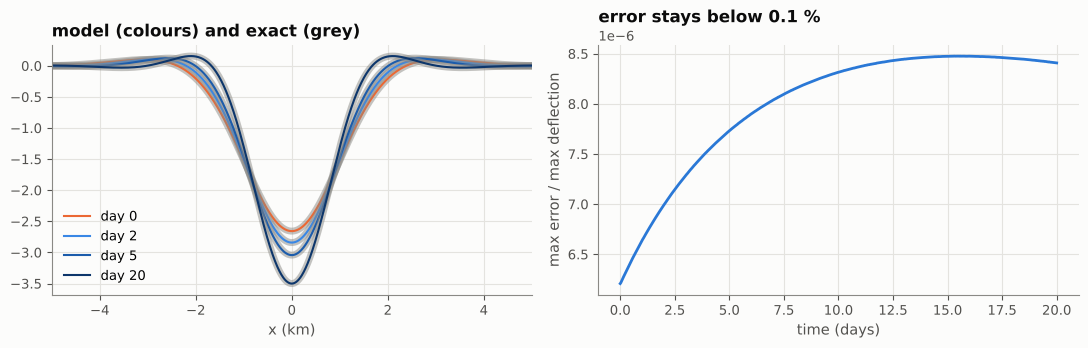

In [8]:
x = np.linspace(-25e3, 25e3, 5001)[:-1]
s = np.clip(x / 1500, -1, 1)
q = shelf.lake_load(4 * np.cos(0.5 * np.pi * s) ** 2)      # smooth lake
t = np.linspace(0, 20 * DAY, 801)
res = ViscoelasticBeam(x, shelf).run(t, lambda _: q)
exact = spectral_step_response(x, q, t, shelf)
err_t = np.abs(res.w - exact).max(axis=1) / np.abs(exact).max()
record("viscoelastic relaxation (exact modes)", err_t.max(), 2e-3)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for tt, c in zip([0, 2, 5, 20], [ps.ELASTIC, ps.SEQ[3], ps.SEQ[6], ps.SEQ[9]]):
    i = np.argmin(abs(t - tt * DAY))
    ax[0].plot(x/1e3, -exact[i], color=ps.MUTED, lw=5, alpha=.5)
    ax[0].plot(x/1e3, -res.w[i], color=c, lw=1.5, label=f"day {tt}")
ax[0].set_xlim(-5, 5); ax[0].legend(); ax[0].set_xlabel("x (km)"); ax[0].set_title("model (colours) and exact (grey)")
ax[1].plot(t/DAY, err_t, color=ps.VISCO); ax[1].set_xlabel("time (days)")
ax[1].set_ylabel("max error / max deflection"); ax[1].set_title("error stays below 0.1 %")
fig.tight_layout(); plt.show()

### 2.5–2.7 Long-time limit, a uniform load, and exact force balance

* A **broad** lake relaxes to local isostasy, $w = q/k$, and its moments vanish within a few tens of $\tau$. A narrow lake would take far longer.
* A load covering the whole free beam causes **no bending at all**.
* The discrete force balance $L^*M + kw = q$ holds to **round-off at every step**, for every combination of boundary conditions.

In [9]:
# 2.5 long-time limit
x = np.linspace(-40e3, 40e3, 1601)
q = shelf.lake_load(4 * np.cos(0.5 * np.pi * np.clip(x / 8e3, -1, 1)) ** 2)
res = ViscoelasticBeam(x, shelf).run(np.linspace(0, 120 * DAY, 481), lambda _: q)
record("long-time limit w -> q/k", np.abs(res.w[-1] - q/shelf.k).max() / (q.max()/shelf.k), 2e-3)
record("long-time limit M -> 0", np.abs(res.M[-1]).max() / np.abs(res.M[0]).max(), 1e-2)

# 2.6 uniform load: floats down without bending
x = np.linspace(0, 10e3, 501); q = np.full_like(x, shelf.lake_load(1.0))
res = ViscoelasticBeam(x, shelf).run(np.linspace(0, 5 * DAY, 11), lambda _: q)
record("uniform load: no bending (M / q ell^2)", np.abs(res.M).max() / (q[0] * shelf.ell**2), 1e-9)

# 2.7 force balance at every step, all boundary-condition combinations
x = np.linspace(0, 20e3, 801); depth = parabolic_lake(x, 6e3, 1.5e3, 4.0)
t = np.linspace(0, 15 * DAY, 151)
for left, right in [("free", "free"), ("clamped", "free"), ("clamped", "clamped")]:
    b = ViscoelasticBeam(x, shelf, left, right)
    r = b.run(t, lambda tt: shelf.lake_load(depth) * min(tt / (5 * DAY), 1.0))
    resid = max(np.abs((b.Lstar @ r.M[i] + shelf.k * r.w[i] - r.q[i])[b.active]).max() for i in range(t.size))
    record(f"force balance ({left}/{right})", resid / shelf.lake_load(4.0), 1e-8)
pd.DataFrame(checks).tail(6)

,test,error,tolerance,passed
4,long-time limit w -> q/k,5.631e-04,2.000e-03,True
5,long-time limit M -> 0,2.536e-03,1.000e-02,True
6,uniform load: no bending (M / q ell^2),9.457e-11,1.000e-09,True
7,force balance (free/free),1.135e-09,1.000e-08,True
8,force balance (clamped/free),8.935e-10,1.000e-08,True
9,force balance (clamped/clamped),1.024e-09,1.000e-08,True


### 2.8 Convergence

The scheme is second-order accurate in both time and space. Halving $\Delta t$ or $\Delta x$ cuts the error by four. Both step sizes are made dimensionless with the physical scales, $\Delta t/\tau$ and $\Delta x/\ell$.

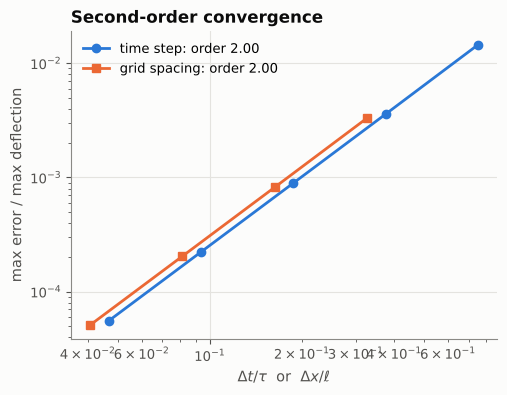

In [10]:
x = np.linspace(-25e3, 25e3, 2501)[:-1]; s = np.clip(x / 1500, -1, 1)
Q = shelf.lake_load(4 * np.cos(0.5 * np.pi * s) ** 2)
T = 6 * shelf.tau
load = lambda tt: Q * np.sin(np.pi * tt / T) ** 2
bm = ViscoelasticBeam(x, shelf)
ref = bm.run(np.linspace(0, T, 8193), load).w[-1]
nts = np.array([8, 16, 32, 64, 128])
et = np.array([np.abs(bm.run(np.linspace(0, T, n + 1), load).w[-1] - ref).max() for n in nts]) / np.abs(ref).max()
ns = np.array([250, 500, 1000, 2000]); ex_ = []
for n in ns:
    xx = np.linspace(-25e3, 25e3, n + 1)[:-1]
    qq = shelf.lake_load(4 * np.cos(0.5 * np.pi * np.clip(xx / 1500, -1, 1)) ** 2)
    ww, _ = ViscoelasticBeam(xx, shelf).elastic(qq)
    e0 = spectral_step_response(xx, qq, [0.0], shelf)[0]
    ex_.append(np.abs(ww - e0).max() / np.abs(e0).max())
ex_ = np.array(ex_)
p_t = np.polyfit(np.log(T / nts), np.log(et), 1)[0]
p_x = np.polyfit(np.log(50e3 / ns), np.log(ex_), 1)[0]
record("time convergence order (>= 1.9)", 2 - min(p_t, 2), 0.1)
record("space convergence order (>= 1.9)", 2 - min(p_x, 2), 0.1)

fig, a = plt.subplots(figsize=(5.5, 4))
a.loglog(T / nts / shelf.tau, et, "o-", color=ps.VISCO, label=f"time step: order {p_t:.2f}")
a.loglog(50e3 / ns / shelf.ell, ex_, "s-", color=ps.ELASTIC, label=f"grid spacing: order {p_x:.2f}")
a.set_xlabel(r"$\Delta t/\tau$  or  $\Delta x/\ell$"); a.set_ylabel("max error / max deflection")
a.legend(); a.set_title("Second-order convergence"); plt.show()

In [11]:
summary = pd.DataFrame(checks)
summary["error"] = summary["error"].map(lambda v: f"{v:.1e}")
summary

,test,error,tolerance,passed
0,elastic strip load (Hetényi),1.7e-03,2.000e-03,True
1,line load at a free front,8.2e-06,2.000e-03,True
2,"uniform load, clamped grounding line",6.5e-06,1.000e-03,True
3,viscoelastic relaxation (exact modes),8.5e-06,2.000e-03,True
4,long-time limit w -> q/k,5.6e-04,2.000e-03,True
5,long-time limit M -> 0,2.5e-03,1.000e-02,True
6,uniform load: no bending (M / q ell^2),9.5e-11,1.000e-09,True
7,force balance (free/free),1.1e-09,1.000e-08,True
8,force balance (clamped/free),8.9e-10,1.000e-08,True
9,force balance (clamped/clamped),1.0e-09,1.000e-08,True


In [12]:
# the same checks as an automated test-suite
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_viscoelastic_beam.py"],
                     capture_output=True, text=True)
print(out.stdout[-400:])

..............                                                           [100%]
14 passed in 2.95s



---
## 3. Two horizontal dimensions: a viscoelastic plate

### 3.1 The equations

Real lakes are not infinitely long troughs. In map view, with coordinates $(x, y)$, the beam becomes a thin plate, and $\partial^4/\partial x^4$ becomes the biharmonic operator $\nabla^4 = (\partial_{xx}+\partial_{yy})^2$.

The force balance becomes $\partial_{xx}M_{xx} + 2\partial_{xy}M_{xy} + \partial_{yy}M_{yy} + kw = q$, with three moment components instead of one. The moment tensor splits into an isotropic part and a deviatoric part. Elastically (Poisson's ratio $\nu$) and viscously ($\nu_v = \tfrac12$) these parts have different proportions, so each is its own Maxwell element with its own time $\tau_i$ (§5 of the derivation).

The bookkeeping stays simple with two scalar **moment potentials** $\mu_1, \mu_2$. Each obeys a beam-like Maxwell law with $w$ in place of the curvature:

$$
\dot\mu_i = D_i\,\dot w - \mu_i/\tau_i,\qquad D_{1,2} = D\,\tfrac{1\pm\nu}{2}, \qquad \nabla^4(\mu_1 + \mu_2) + kw = q,
$$
$$
\mathbf M = \nabla^2\mu_1\,I + 2\,\nabla\nabla\mu_2 - \nabla^2\mu_2\,I .
$$

Some consequences:

* **Elastic limit.** $\mu_i = D_i w$, which gives the textbook plate moments $D[(1-\nu)\nabla\nabla w + \nu\nabla^2 w\,I]$.
* **Viscous limit.** The moments become $\Lambda[(1-\nu_v)\dot{\boldsymbol\kappa} + \nu_v\,\mathrm{tr}(\dot{\boldsymbol\kappa})I]$, which for $\nu_v=\tfrac12$ is exactly the viscous plate of MacAyeal et al. (2021) and Bézu et al. (2025).
* **Equal Poisson's ratios.** With $\nu_v=\nu$ the two times coincide, and the deflection obeys $(D\nabla^4 + k)\dot w = \dot q + (q-kw)/\tau$.
* **Stresses.** The upper-surface stresses are $\sigma_{ij} = 6M_{ij}/H^2$. For fracture the relevant quantity is the **largest principal stress** $\sigma_1$, positive in tension.
* **The beam is a special case.** A lake that does not vary in $y$ gives exactly the 1-D plane-strain beam. Test 3.3(b) checks this.

### 3.2 Two solvers

| | `SpectralPlate` | `FDPlate` |
|---|---|---|
| domain | periodic rectangle | rectangle with clamped or periodic edges, plus a mask of fixed (grounded) nodes |
| space | Fourier modes (exact derivatives) | 13-point finite-difference biharmonic, second order |
| time | **exact** for loads that vary linearly between the given times | Crank–Nicolson (same scheme as the beam) |
| linear algebra | none: one FFT pair per step | sparse LU (factorised once) or conjugate gradients with a fast-sine-transform preconditioner |
| use it for | lakes on a large, uniform floating shelf; speed | grounding lines and other fixed boundaries |

For the spectral solver, take a Fourier mode with $K^4 = (k_x^2+k_y^2)^2$ and $A = DK^4 + k$. Its two potentials obey the linear system $\dot{\boldsymbol\mu} = (\mathbf d/A)\,\dot Q - G\,\boldsymbol\mu$, with $\mathbf d = (D_1, D_2)$ and a $2\times2$ matrix $G$, and the deflection follows from force balance, $W = (Q - K^4(\mu_1+\mu_2))/k$. Over a step in which $Q$ changes linearly with slope $s$, the exact solution is

$$
\boldsymbol\mu_1 = e^{-G\Delta t}\,\boldsymbol\mu_0 + \Big[\int_0^{\Delta t} e^{-Gt'}\,dt'\Big]\frac{\mathbf d}{A}\,s .
$$

The coefficients are computed once per $\Delta t$ (see `SpectralPlate.step_coefficients`). So **the time step never has to resolve the physics**, only the corners of the load history. Part 4 makes use of this.

512x512 grid, 4 output times: 0.20 s


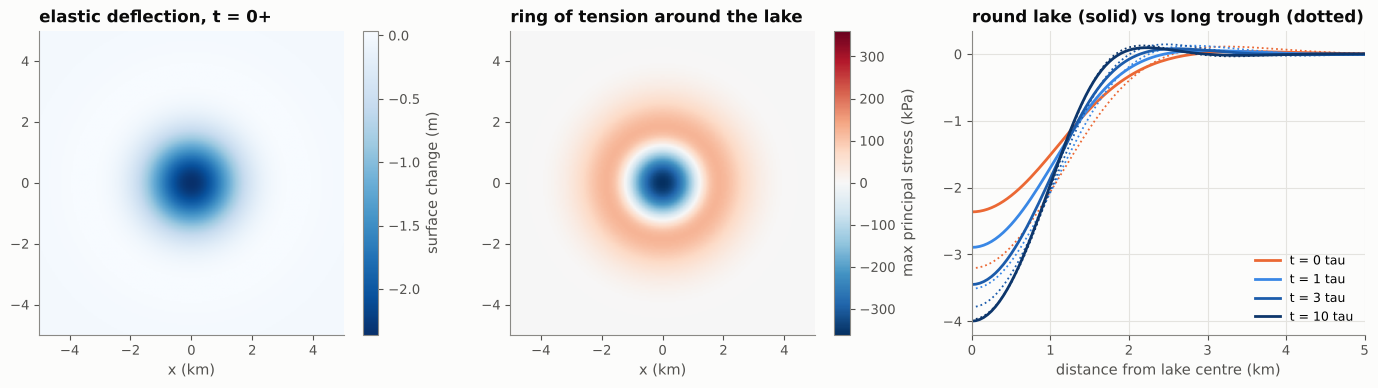

elastic centre dip: round lake 2.36 m, trough 3.20 m, isostatic 3.89 m


In [13]:
# a circular lake (radius 1.5 km, 4 m deep) on a 25.6 km x 25.6 km periodic domain, 50 m grid
n, dx = 512, 50.0
xg = (np.arange(n) - n / 2) * dx
X, Y = np.meshgrid(xg, xg); R = np.hypot(X, Y)
depth2 = parabolic_lake(R, 0.0, 1500.0, 4.0)
Q2 = shelf.lake_load(depth2)

plate = SpectralPlate(n, n, dx, shelf)
t_out = np.array([0, 1, 3, 10]) * shelf.tau
t0 = time.perf_counter()
r2 = plate.run(t_out, (Q2, np.ones(t_out.size)))       # separable load Q(x, y) * f(t)
print(f"{n}x{n} grid, 4 output times: {time.perf_counter() - t0:.2f} s")

# the 1-D equivalent: an infinitely long trough with the same cross-section
xb = np.linspace(-15e3, 15e3, 3001)
rb = ViscoelasticBeam(xb, shelf).run(np.linspace(0, 10 * shelf.tau, 401),
                                     lambda _: shelf.lake_load(parabolic_lake(xb, 0, 1500, 4)))

j0 = n // 2
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
im = ax[0].imshow(-r2.w[0], extent=[xg[0]/1e3, xg[-1]/1e3, xg[0]/1e3, xg[-1]/1e3], cmap="Blues_r", origin="lower")
fig.colorbar(im, ax=ax[0], label="surface change (m)"); ax[0].set_title("elastic deflection, t = 0+")
sxx, syy, sxy = plate.surface_stress(r2.mu[0]); s1, _ = principal_stresses(sxx, syy, sxy)
lim = np.abs(s1).max() / 1e3
im = ax[1].imshow(s1 / 1e3, extent=[xg[0]/1e3, xg[-1]/1e3, xg[0]/1e3, xg[-1]/1e3], cmap="RdBu_r", vmin=-lim, vmax=lim, origin="lower")
fig.colorbar(im, ax=ax[1], label="max principal stress (kPa)"); ax[1].set_title("ring of tension around the lake")
for a in ax[:2]:
    a.set_xlim(-5, 5); a.set_ylim(-5, 5); a.grid(False); a.set_xlabel("x (km)")
for i, (tt, c) in enumerate(zip(t_out, [ps.ELASTIC, ps.SEQ[3], ps.SEQ[6], ps.SEQ[9]])):
    ib = np.argmin(abs(rb.t - tt))
    ax[2].plot(xg / 1e3, -r2.w[i, j0], color=c, label=f"t = {tt/shelf.tau:g} tau")
    ax[2].plot(xb / 1e3, -rb.w[ib], color=c, ls=":", lw=1.3)
ax[2].set_xlim(0, 5); ax[2].set_xlabel("distance from lake centre (km)")
ax[2].set_title("round lake (solid) vs long trough (dotted)"); ax[2].legend(fontsize=9)
fig.tight_layout(); plt.show()
print(f"elastic centre dip: round lake {r2.w[0, j0, j0]:.2f} m, trough {rb.w[0, 1500]:.2f} m, "
      f"isostatic {Q2.max()/shelf.k:.2f} m")

The plate can spread a round lake's weight in every direction, so a **round lake initially sinks less than a long trough** of the same cross-section. Its edges are also held up elastically for longer, because a round lake is a "narrow" feature in two directions at once. The tension ring sits just outside the shoreline, as in 1-D.

### 3.3 Verification in 2-D

| test | exact or reference solution |
|---|---|
| (a) point load on an elastic plate | $w = -\dfrac{P\ell^2}{2\pi D}\,\mathrm{kei}(r/\ell)$ (Kelvin function), $w(0) = P/8\sqrt{kD}$ |
| (b) lake uniform in $y$ | the 1-D beam's exact Fourier solution |
| (c) finite differences vs spectral | the two independent solvers agree |
| (d) exact time integration | one 25-day step equals 200 small ones |
| (e) force balance with a grounded mask | $\nabla^4\mu + kw = q$ to round-off; $w = 0$ on grounded ice |
| (f) long-time limit | local isostasy |

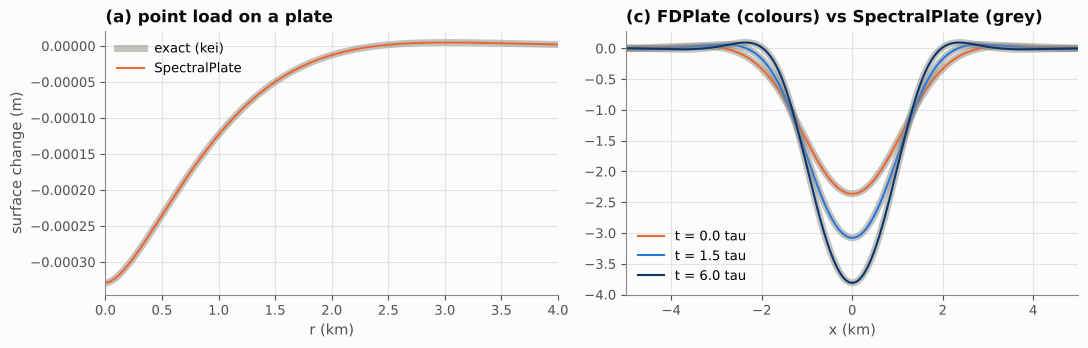

,test,error,tolerance,passed
0,(a) point load: centre,2.2e-04,1.000e-03,True
1,(a) point load: r > 2 dx,7.0e-06,1.000e-04,True
2,(b) y-uniform lake = beam (spectral),4.8e-16,1.000e-12,True
3,(b) y-uniform lake = beam (finite differences),6.1e-04,2.000e-03,True
4,(c) FD vs spectral: deflection,3.3e-04,2.000e-03,True
5,(c) FD vs spectral: stress,4.9e-04,5.000e-03,True
6,(d) exact in time: 1 step vs 200,6.7e-16,1.000e-09,True
7,(e) force balance with grounded mask,1.0e-10,1.000e-08,True
8,(e) w on grounded nodes,0.0e+00,1.000e-300,True
9,(f) long-time limit w -> q/k,5.8e-04,2.000e-03,True


In [14]:
checks2 = []
def record2(name, err, tol):
    checks2.append(dict(test=name, error=f"{err:.1e}", tolerance=tol, passed=bool(err < tol)))

# (a) point load vs the Kelvin-function solution
n, dx, P = 512, 40.0, 1.0e7
qp = np.zeros((n, n)); qp[n//2, n//2] = P / dx**2
wp = SpectralPlate(n, n, dx, shelf).elastic(qp)
xp = (np.arange(n) - n//2) * dx; Rp = np.hypot(*np.meshgrid(xp, xp))
exp_ = point_load_plate(Rp, P, shelf)
record2("(a) point load: centre", abs(wp[n//2, n//2] / exp_[n//2, n//2] - 1), 1e-3)
record2("(a) point load: r > 2 dx", np.abs(wp - exp_)[Rp > 2*dx].max() / exp_.max(), 1e-4)

# (b) lake uniform in y == the 1-D beam
xx = np.linspace(-25e3, 25e3, 1251)[:-1]
q1 = shelf.lake_load(4 * np.cos(0.5 * np.pi * np.clip(xx / 1500, -1, 1)) ** 2)
tt = np.linspace(0, 10 * shelf.tau, 21)
ex1 = spectral_step_response(xx, q1, tt, shelf)
rr = SpectralPlate(xx.size, 4, xx[1] - xx[0], shelf).run(tt, (np.tile(q1, (4, 1)), np.ones(tt.size)))
record2("(b) y-uniform lake = beam (spectral)", np.abs(rr.w[:, 2] - ex1).max() / np.abs(ex1).max(), 1e-12)
rf = FDPlate(xx.size, 4, xx[1] - xx[0], shelf, edges="periodic").run(tt, lambda _: np.tile(q1, (4, 1)))
record2("(b) y-uniform lake = beam (finite differences)", np.abs(rf.w[:, 2] - ex1).max() / np.abs(ex1).max(), 2e-3)

# (c) FD vs spectral, circular lake, viscoelastic run
n, dx = 192, 60.0
xc = (np.arange(n) - n/2) * dx; Rc = np.hypot(*np.meshgrid(xc, xc))
Qc = shelf.lake_load(parabolic_lake(Rc, 0, 1500, 4))
tt = np.linspace(0, 6 * shelf.tau, 41)
fdp = FDPlate(n, n, dx, shelf, edges="periodic"); rfd = fdp.run(tt, lambda _: Qc)
spp = SpectralPlate(n, n, dx, shelf); rsp = spp.run(tt, (Qc, np.ones(tt.size)))
record2("(c) FD vs spectral: deflection", np.abs(rfd.w - rsp.w).max() / np.abs(rsp.w).max(), 2e-3)
s_fd = fdp.surface_stress(rfd.mu[0])[0]; s_sp = spp.surface_stress(rsp.mu[0])[0]
record2("(c) FD vs spectral: stress", np.abs(s_fd - s_sp).max() / np.abs(s_sp).max(), 5e-3)

# (d) one big step == many small steps
tf = 25 * DAY; f = lambda s_: min(s_ / tf, 1.0)
fine = spp.run(np.linspace(0, tf, 201), (Qc, f), store=[200]).w[-1]
coarse = spp.run([0.0, tf], (Qc, f), store=[1]).w[-1]
record2("(d) exact in time: 1 step vs 200", np.abs(fine - coarse).max() / np.abs(fine).max(), 1e-9)

# (e) force balance with a grounded region
fixed = np.zeros((96, 96), bool); fixed[:, :20] = True
xe = (np.arange(96) - 48) * 60.0; Re = np.hypot(*np.meshgrid(xe, xe))
Qe = shelf.lake_load(parabolic_lake(Re, 0, 1500, 4))
fde = FDPlate(96, 96, 60.0, shelf, fixed=fixed)
te = np.linspace(0, 15 * DAY, 31)
re = fde.run(te, lambda s_: Qe * fill_hold_drain(s_, 5*DAY, 5*DAY, 0.5*DAY))
resid = max(np.abs(fde.force_residual(re.w[i], re.mu[i], re.q[i])).max() for i in range(te.size))
record2("(e) force balance with grounded mask", resid / Qe.max(), 1e-8)
record2("(e) w on grounded nodes", np.abs(re.w[:, fixed]).max(), 1e-300)

# (f) long-time limit for a broad smooth lake
xf = (np.arange(128) - 64) * 250.0; Rf = np.hypot(*np.meshgrid(xf, xf))
Qf = shelf.lake_load(4 * np.cos(0.5 * np.pi * np.clip(Rf / 8000, 0, 1)) ** 2)
wf = SpectralPlate(128, 128, 250.0, shelf).run([0, 30 * shelf.tau], (Qf, [1, 1])).w[-1]
record2("(f) long-time limit w -> q/k", np.abs(wf - Qf/shelf.k).max() / (Qf.max()/shelf.k), 2e-3)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
rr_ = np.linspace(0, 4000, 400)
ax[0].plot(rr_/1e3, -point_load_plate(rr_, P, shelf), color=ps.MUTED, lw=5, alpha=.5, label="exact (kei)")
ax[0].plot(xp[256:]/1e3, -wp[256, 256:], "-", color=ps.ELASTIC, lw=1.5, label="SpectralPlate")
ax[0].set_xlim(0, 4); ax[0].set_xlabel("r (km)"); ax[0].set_ylabel("surface change (m)"); ax[0].legend()
ax[0].set_title("(a) point load on a plate")
jc = 96
for i, c in zip([0, 10, 40], [ps.ELASTIC, ps.SEQ[4], ps.SEQ[9]]):
    ax[1].plot(xc/1e3, -rsp.w[i, jc], color=ps.MUTED, lw=5, alpha=.5)
    ax[1].plot(xc/1e3, -rfd.w[i, jc], color=c, lw=1.5, label=f"t = {tt[i]/shelf.tau:.1f} tau")
ax[1].set_xlim(-5, 5); ax[1].legend(); ax[1].set_xlabel("x (km)"); ax[1].set_title("(c) FDPlate (colours) vs SpectralPlate (grey)")
fig.tight_layout(); plt.show()
pd.DataFrame(checks2)

In [15]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_viscoelastic_plate.py"],
                     capture_output=True, text=True)
print(out.stdout[-400:])

..........                                                               [100%]
10 passed in 4.96s



### 3.4 A round lake fills, sits and drains

This is the 2-D version of the cycle in §9 of the derivation. The run uses the spectral solver with time steps **only** where something happens: the corners of the fill–hold–drain history and the four output times. That is 7 steps in total, and the result is exact.

4 exact steps on 512x512: 0.20 s


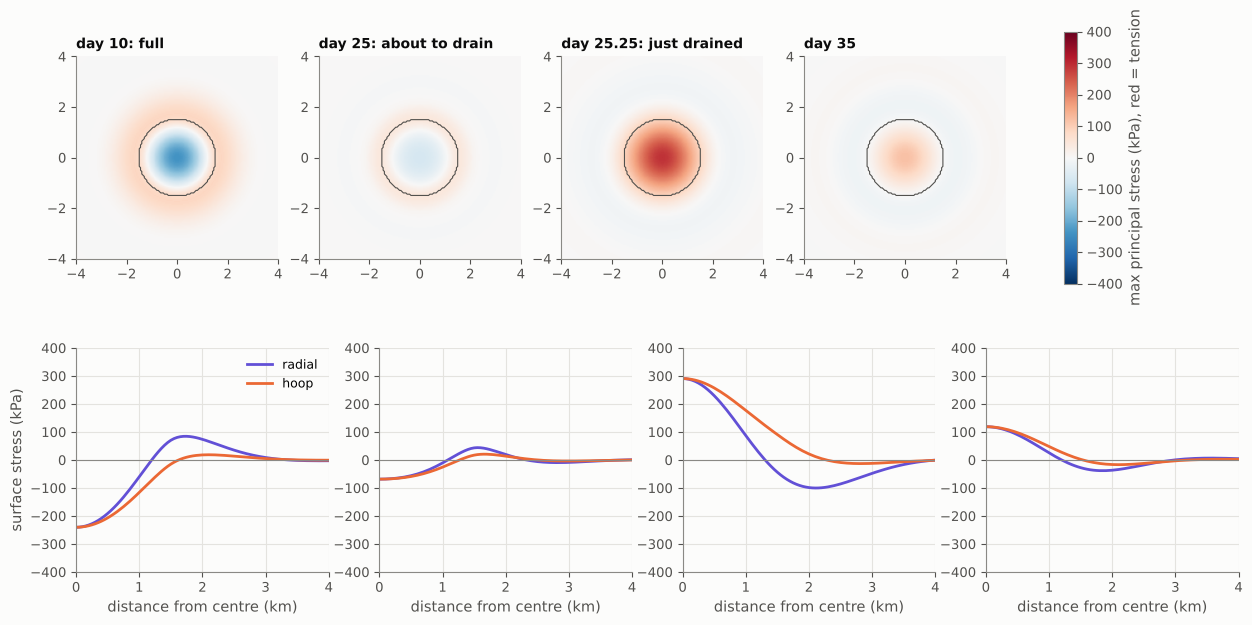

In [16]:
n, dx = 512, 50.0
plate = SpectralPlate(n, n, dx, shelf)
tf, th, tdr = 10 * DAY, 15 * DAY, 0.25 * DAY
hist = lambda s_: fill_hold_drain(s_, tf, th, tdr)
outs = np.array([10, 25, 25.25, 35]) * DAY
t_steps = np.unique(np.r_[0, tf, tf + th, tf + th + tdr, outs])
store = [int(np.flatnonzero(t_steps == o)[0]) for o in outs]
t0 = time.perf_counter()
r4 = plate.run(t_steps, (Q2, hist), store=store)
print(f"{len(t_steps) - 1} exact steps on {n}x{n}: {time.perf_counter() - t0:.2f} s")

titles = ["day 10: full", "day 25: about to drain", "day 25.25: just drained", "day 35"]
fig, ax = plt.subplots(2, 4, figsize=(15, 7.2), gridspec_kw=dict(height_ratios=[1, 0.8]))
ext = [xg[0]/1e3, xg[-1]/1e3, xg[0]/1e3, xg[-1]/1e3]
lim = 400
for i in range(4):
    sxx, syy, sxy = plate.surface_stress(r4.mu[i]); s1, _ = principal_stresses(sxx, syy, sxy)
    im = ax[0, i].imshow(s1/1e3, extent=ext, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax[0, i].contour(xg/1e3, xg/1e3, Q2, levels=[1.0], colors=ps.INK2, linewidths=0.8)
    ax[0, i].set_xlim(-4, 4); ax[0, i].set_ylim(-4, 4); ax[0, i].set_title(titles[i], fontsize=10); ax[0, i].grid(False)
    # radial (sxx) and hoop (syy) stress along the x-axis
    ax[1, i].plot(xg[j0:]/1e3, sxx[j0, j0:]/1e3, color=ps.ACCENT, label="radial")
    ax[1, i].plot(xg[j0:]/1e3, syy[j0, j0:]/1e3, color=ps.ELASTIC, label="hoop")
    ax[1, i].axhline(0, color=ps.MUTED, lw=0.8); ax[1, i].set_xlim(0, 4); ax[1, i].set_ylim(-lim, lim)
    ax[1, i].set_xlabel("distance from centre (km)")
ax[1, 0].set_ylabel("surface stress (kPa)"); ax[1, 0].legend(fontsize=9)
fig.colorbar(im, ax=ax[0, :], label="max principal stress (kPa), red = tension", shrink=0.9)
plt.show()

The pattern matches 1-D:

* **While the lake fills**, a ring of radial tension forms just outside the shore.
* **While it sits**, the stresses relax.
* **When it drains**, the stress flips and the surface where the lake was goes into tension. In 2-D this tension is equal in all directions at the centre (radial = hoop).

### 3.5 What the viscous Poisson's ratio changes

The same cycle is run twice: once with incompressible creep (the default, `nu_v = 0.5`, two relaxation times) and once with `nu_v = nu` (the single-time model). The two parts of the moment relax at different rates. The isotropic part, which dominates under the middle of a round lake, takes $\tau_1 \approx 4.9$ days; the deviatoric part takes $\tau_2 \approx 3.0$ days. A single time of 4.2 days averages over the two.

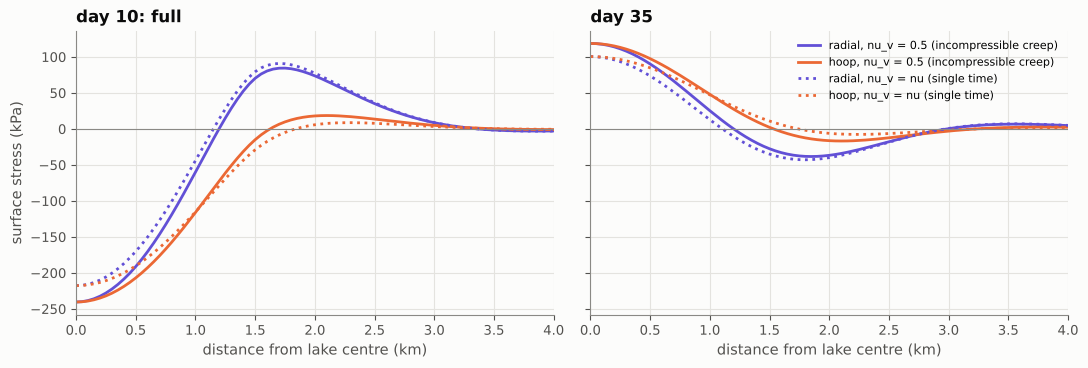

centre dip (m)  \
time                    model                                               
day 10: full            nu_v = 0.5 (incompressible creep)            2.93   
                        nu_v = nu (single time)                      2.92   
day 25: about to drain  nu_v = 0.5 (incompressible creep)            3.69   
                        nu_v = nu (single time)                      3.69   
day 25.25: just drained nu_v = 0.5 (incompressible creep)            1.31   
                        nu_v = nu (single time)                      1.32   
day 35                  nu_v = 0.5 (incompressible creep)            0.57   
                        nu_v = nu (single time)                      0.57   

                                                           centre stress (kPa)  \
time                    model                                                    
day 10: full            nu_v = 0.5 (incompressible creep)              -240.44   
                        nu_v = nu (single time)                        -217.73   
day 25: about to drain  nu_v = 0.5 (incompressible creep)               -68.59   
                        nu_v = nu (single time)                         -56.18   
day 25.25: just drained nu_v = 0.5 (incompressible creep)               290.66   
                        nu_v = nu (single time)                         301.20   
day 35                  nu_v = 0.5 (incompressible creep)               118.68   
                        nu_v = nu (single time)                         100.43   

                                                           max radial (kPa)  \
time                    model                                                 
day 10: full            nu_v = 0.5 (incompressible creep)             84.41   
                        nu_v = nu (single time)                       90.88   
day 25: about to drain  nu_v = 0.5 (incompressible creep)             43.97   
                        nu_v = nu (single time)                       46.41   
day 25.25: just drained nu_v = 0.5 (incompressible creep)            290.66   
                        nu_v = nu (single time)                      301.20   
day 35                  nu_v = 0.5 (incompressible creep)            118.68   
                        nu_v = nu (single time)                      100.43   

                                                           max hoop (kPa)  
time                    model                                              
day 10: full            nu_v = 0.5 (incompressible creep)           18.53  
                        nu_v = nu (single time)                      8.67  
day 25: about to drain  nu_v = 0.5 (incompressible creep)           20.56  
                        nu_v = nu (single time)                     10.65  
day 25.25: just drained nu_v = 0.5 (incompressible creep)          290.66  
                        nu_v = nu (single time)                    301.20  
day 35                  nu_v = 0.5 (incompressible creep)          118.68  
                        nu_v = nu (single time)                    100.43

In [17]:
rows, prof = [], {}
whens = ["day 10: full", "day 25: about to drain", "day 25.25: just drained", "day 35"]
models = [("nu_v = 0.5 (incompressible creep)", shelf), ("nu_v = nu (single time)", IceShelf(nu_v=shelf.nu))]
for lab, s_ in models:
    p_ = SpectralPlate(n, n, dx, s_)
    rr = p_.run(t_steps, (s_.lake_load(depth2), hist), store=store)
    for i, when in enumerate(whens):
        sxx, syy, sxy = p_.surface_stress(rr.mu[i])
        rows.append({"model": lab, "time": when, "centre dip (m)": rr.w[i, j0, j0],
                     "centre stress (kPa)": sxx[j0, j0] / 1e3,
                     "max radial (kPa)": sxx[j0, j0:].max() / 1e3, "max hoop (kPa)": syy[j0, j0:].max() / 1e3})
        prof[(lab, i)] = (sxx[j0, j0:] / 1e3, syy[j0, j0:] / 1e3)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for k_, i in enumerate([0, 3]):
    for (lab, _), ls in zip(models, ["-", ":"]):
        rad, hoop = prof[(lab, i)]
        ax[k_].plot(xg[j0:] / 1e3, rad, ls, color=ps.ACCENT, label=f"radial, {lab}")
        ax[k_].plot(xg[j0:] / 1e3, hoop, ls, color=ps.ELASTIC, label=f"hoop, {lab}")
    ax[k_].axhline(0, color=ps.MUTED, lw=0.8); ax[k_].set_xlim(0, 4)
    ax[k_].set_title(whens[i]); ax[k_].set_xlabel("distance from lake centre (km)")
ax[0].set_ylabel("surface stress (kPa)"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
tab_nu = pd.DataFrame(rows)
tab_nu["time"] = pd.Categorical(tab_nu["time"], whens, ordered=True)
tab_nu.sort_values("time", kind="stable").set_index(["time", "model"]).round(2)

The deflections are the same to within about a centimetre, but the stresses are not:

* **At the end of filling**, the compression under the lake is about 10% larger with incompressible creep. The isotropic part of the bending there relaxes more slowly.
* **Near the shore**, the hoop tension is roughly twice as large, although it stays small.
* **Ten days after drainage**, the tension left at the old lake centre is about 20% larger.

So the viscous Poisson's ratio matters for fracture thresholds, even though it barely affects the deflection.

### 3.6 A real lake map from this repository

`python/notebooks/fsm_results/rema_tests/test-wtd.tif` is a water-depth map produced by the fill-spill-merge routing in this repository. It is on the 32 m grid of the REMA subset `dem_small_2.tif`. We take a 33 km × 33 km window and run the same fill–hold–drain history with two set-ups:

1. **`SpectralPlate` at the full 32 m resolution**, treating all the ice as floating.
2. **`FDPlate` at 128 m**, holding grounded ice fixed. Grounded ice is taken from `data/Mask_Antarctica_v02.tif` (500 m; value 125 is floating, 255 is grounded).

Caveats: the thickness is uniform (250 m), the lake depths are taken as given, and the grounding line is only as good as a 500 m mask. Treat this as a demonstration of the machinery, not a study of this ice shelf.

In [18]:
try:
    import tifffile
except ImportError:
    tifffile = None
    print("pip install tifffile to run this example")

if tifffile is not None:
    wtd = tifffile.imread("../python/notebooks/fsm_results/rema_tests/test-wtd.tif")
    mask500 = tifffile.imread("../data/Mask_Antarctica_v02.tif")
    r0, nwin, px = 1024, 1024, 32.0                     # window rows r0:r0+1024, all 1024 columns
    ii = np.arange(wtd.shape[0]); jj = np.arange(wtd.shape[1])
    ys = 2000012 - px * (ii + 0.5); xs = 799988 + px * (jj + 0.5)  # polar-stereographic coordinates
    grounded_full = mask500[((2799750 - ys) / 500).astype(int)[:, None], ((xs + 2799750) / 500).astype(int)[None, :]] == 255
    lake = np.clip(np.nan_to_num(wtd[r0:r0 + nwin]), 0, None)
    grounded = grounded_full[r0:r0 + nwin]
    print(f"window {nwin * px / 1e3:.1f} km square, lake volume {lake.sum() * px**2 / 1e6:.0f} million m^3, "
          f"max depth {lake.max():.1f} m, grounded fraction {grounded.mean():.2f}")

window 32.8 km square, lake volume 378 million m^3, max depth 31.8 m, grounded fraction 0.34


spectral 1024x1024 at 32 m, 3 exact steps: 1.9 s
FD 256x256 at 128 m with grounding, 101 Crank-Nicolson steps: 4.3 s


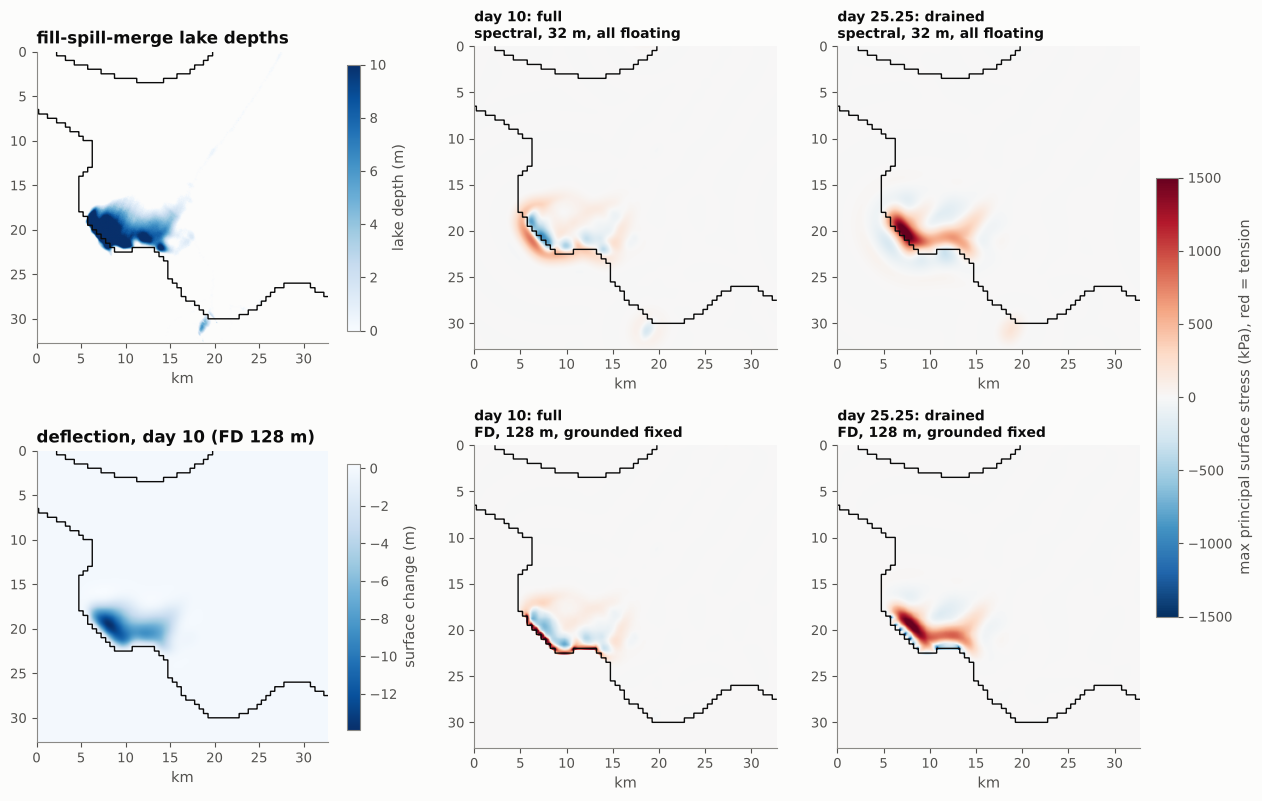

In [19]:
if tifffile is not None:
    tf, th, tdr = 10 * DAY, 15 * DAY, 0.25 * DAY
    hist = lambda s_: fill_hold_drain(s_, tf, th, tdr)
    outs = np.array([10, 25.25]) * DAY
    t_steps = np.unique(np.r_[0, tf, tf + th, tf + th + tdr, outs])
    store = [int(np.flatnonzero(t_steps == o)[0]) for o in outs]

    # (1) spectral, 32 m, everything floating
    sp32 = SpectralPlate(nwin, nwin, px, shelf)
    t0 = time.perf_counter()
    rs32 = sp32.run(t_steps, (shelf.lake_load(lake), hist), store=store)
    s1_32 = [principal_stresses(*sp32.surface_stress(rs32.mu[i]))[0] for i in range(2)]
    t_sp = time.perf_counter() - t0

    # (2) finite differences, 128 m, grounded ice held fixed (block-average the 32 m data)
    b = 4; m_ = nwin // b
    lake128 = lake.reshape(m_, b, m_, b).mean(axis=(1, 3))
    grounded128 = grounded.reshape(m_, b, m_, b).mean(axis=(1, 3)) > 0.5
    fd128 = FDPlate(m_, m_, px * b, shelf, edges="clamped", fixed=grounded128)
    t_cn = np.arange(0, 25.25 * DAY + 1, 0.25 * DAY)        # Crank-Nicolson needs dt << tau
    store_fd = [int(np.argmin(abs(t_cn - o))) for o in outs]
    t0 = time.perf_counter()
    rf128 = fd128.run(t_cn, lambda s_: shelf.lake_load(lake128) * hist(s_), store=store_fd)
    s1_128 = [principal_stresses(*fd128.surface_stress(rf128.mu[i]))[0] for i in range(2)]
    t_fd = time.perf_counter() - t0
    print(f"spectral {nwin}x{nwin} at 32 m, {len(t_steps) - 1} exact steps: {t_sp:.1f} s")
    print(f"FD {m_}x{m_} at 128 m with grounding, {len(t_cn) - 1} Crank-Nicolson steps: {t_fd:.1f} s")

    ext = [0, nwin * px / 1e3, nwin * px / 1e3, 0]
    fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))
    im = ax[0, 0].imshow(np.where(lake > 0.05, lake, np.nan), extent=ext, cmap="Blues", vmin=0, vmax=10)
    fig.colorbar(im, ax=ax[0, 0], shrink=0.8, label="lake depth (m)")
    ax[0, 0].set_title("fill-spill-merge lake depths")
    im = ax[1, 0].imshow(-rf128.w[0], extent=ext, cmap="Blues_r")
    fig.colorbar(im, ax=ax[1, 0], shrink=0.8, label="surface change (m)")
    ax[1, 0].set_title("deflection, day 10 (FD 128 m)")
    lim = 1500
    for k_, (s1s, lab) in enumerate([(s1_32, "spectral, 32 m, all floating"), (s1_128, "FD, 128 m, grounded fixed")]):
        for i, when in enumerate(["day 10: full", "day 25.25: drained"]):
            a = ax[k_, 1 + i]
            im = a.imshow(s1s[i] / 1e3, extent=ext, cmap="RdBu_r", vmin=-lim, vmax=lim)
            a.set_title(f"{when}\n{lab}", fontsize=10)
    fig.colorbar(im, ax=ax[:, 1:], shrink=0.6, pad=0.02, label="max principal surface stress (kPa), red = tension")
    for a in ax.ravel():
        a.contour(np.linspace(0, nwin * px / 1e3, nwin), np.linspace(0, nwin * px / 1e3, nwin), grounded.astype(float),
                  levels=[0.5], colors=ps.INK, linewidths=1.0)
        a.set_xlabel("km"); a.grid(False)
    plt.show()

The black contour is the grounding line. The deep lake (up to about 30 m in this map) produces stresses of several hundred kPa to over 1 MPa, well above typical ice tensile strengths. Holding the grounded ice fixed changes the pattern only near the grounding line. Away from it the two set-ups agree, even though the finite-difference run uses a grid four times coarser.

---
## 4. Computation time, and how to make it fast

### 4.1 Where the time goes in 1-D

A time step of `ViscoelasticBeam` does four things: two sparse matrix–vector products, one banded triangular solve with the factorised matrix, and a vector update. Each is $O(N)$ arithmetic, but with $N = 3000$ nodes that arithmetic is only microseconds. Most of the cost is **Python overhead**: function calls, temporary arrays and fancy indexing.

In [20]:
x = np.linspace(-15e3, 15e3, 3001); beam = ViscoelasticBeam(x, shelf)
q = shelf.lake_load(parabolic_lake(x, 0, 1500, 4)); dt = 0.05 * DAY
lu, S, c, a = beam._step_matrices(dt)
w0, M0 = beam.elastic(q); Mp0 = beam.split_moment(M0)    # the two moment parts
parts = {
    "S @ w (sparse product)": lambda: S @ w0,
    "L* @ M (sparse product)": lambda: beam.Lstar @ (c * (1 - a/2) * Mp0).sum(axis=0),
    "banded LU solve": lambda: lu.solve(q),
    "M update (L @ dw)": lambda: c * ((1 - a/2) * Mp0 + beam.Dp * (beam.L @ (w0 - w0))),
    "whole step()": lambda: beam.step(w0, Mp0, q, dt),
}
reps = 2000
pd.DataFrame({k: [best_time(lambda f=f: [f() for _ in range(reps)]) / reps * 1e6] for k, f in parts.items()},
             index=["microseconds per call"]).T

,microseconds per call
S @ w (sparse product),17.510
L* @ M (sparse product),45.063
banded LU solve,68.015
M update (L @ dw),64.804
whole step(),216.542


### 4.2 Faster 1-D loops

[`fast_beam.py`](fast_beam.py) contains two drop-in replacements for the time loop. Both use the same discretisation and give the same answer to about $10^{-9}$, which is round-off amplified by the conditioning of the fourth-derivative matrix.

* `run_banded` stays in NumPy/SciPy. It factorises once with LAPACK `dgbtrf`, solves with `dgbtrs`, and replaces the sparse products with array slices. This tests whether better *library calls* help.
* `run_numba` compiles the whole loop with Numba: banded products, a pentadiagonal solve and the moment update. This removes the Python interpreter from the loop. The compiled code is cached on disk after the first call.

For comparison, two **exact** options are included. On a periodic domain the 1-D problem is just `SpectralPlate` with a single row (`ny = 1`). Its time integration is exact, so it can either take the same steps or jump straight to the outputs.

In [21]:
if fast_beam.HAVE_NUMBA:      # compile once (cached on disk afterwards)
    xx = np.linspace(0, 1e3, 11); bb = ViscoelasticBeam(xx, shelf)
    t0 = time.perf_counter(); fast_beam.run_numba(bb, np.linspace(0, DAY, 3), np.zeros(11), np.ones(3))
    print(f"numba compile/load: {time.perf_counter() - t0:.2f} s")

nt = 200
rows = []
for N in [1001, 3001, 10001, 30001]:
    x = np.linspace(-15e3, 15e3, N); bm = ViscoelasticBeam(x, shelf)
    Q = shelf.lake_load(parabolic_lake(x, 0, 1500, 4))
    t = np.linspace(0, 40 * DAY, nt + 1); f = fill_hold_drain(t, 10*DAY, 15*DAY, 0.25*DAY)
    load = lambda tt: Q * fill_hold_drain(tt, 10*DAY, 15*DAY, 0.25*DAY)
    row = dict(N=N)
    row["reference run()"] = best_time(lambda: bm.run(t, load), 2) / nt
    row["run_banded"] = best_time(lambda: fast_beam.run_banded(bm, t, Q, f), 2) / nt
    if fast_beam.HAVE_NUMBA:
        row["run_numba"] = best_time(lambda: fast_beam.run_numba(bm, t, Q, f), 3) / nt
    sp1 = SpectralPlate(N - 1, 1, x[1] - x[0], shelf)
    row["spectral, same steps"] = best_time(lambda: sp1.run(t, (Q[None, :-1], f), store=[nt]), 3) / nt
    rows.append(row)
t1d = pd.DataFrame(rows).set_index("N")
(t1d * 1e6).round(1).rename(columns=lambda c: c + " [us/step]")

numba compile/load: 0.17 s


,reference run() [us/step],run_banded [us/step],run_numba [us/step],"spectral, same steps [us/step]"
N,,,,
1001,139.4,105.8,30.2,26.2
3001,270.7,257.9,71.1,43.7
10001,714.5,764.2,229.1,100.3
30001,2376.1,2850.2,939.8,331.3


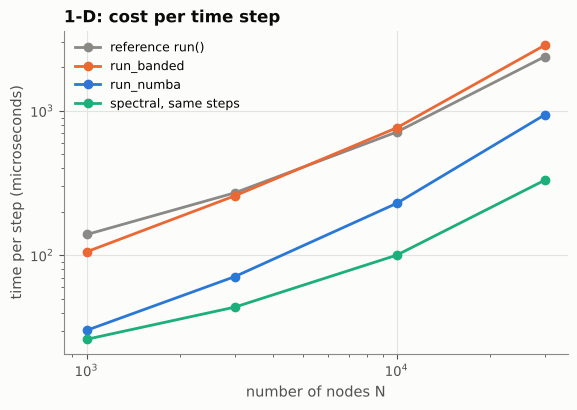

            run_banded: speed-up over the reference loop N=1001: x1.3, N=3001: x1.0, N=10001: x0.9, N=30001: x0.8
             run_numba: speed-up over the reference loop N=1001: x4.6, N=3001: x3.8, N=10001: x3.1, N=30001: x2.5
  spectral, same steps: speed-up over the reference loop N=1001: x5.3, N=3001: x6.2, N=10001: x7.1, N=30001: x7.2


In [22]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
cols = [ps.MUTED, ps.ELASTIC, ps.VISCO, ps.ISO]
for c, col in zip(t1d.columns, cols):
    ax.loglog(t1d.index, t1d[c] * 1e6, "o-", color=col, label=c)
ax.set_xlabel("number of nodes N"); ax.set_ylabel("time per step (microseconds)")
ax.set_title("1-D: cost per time step"); ax.legend(fontsize=9); plt.show()
ref_ = t1d["reference run()"]
for c in t1d.columns[1:]:
    print(f"{c:>22s}: speed-up over the reference loop", ", ".join(f"N={n}: x{v:.1f}" for n, v in (ref_ / t1d[c]).items()))

What this shows:

* **Better library calls don't help.** `run_banded` is no faster than `run()`. The cost is the *number* of Python-level operations per step, each with its own overhead and temporary array, not the arithmetic inside them.
* **Compiling the loop does help.** `run_numba` is 2–4× faster. What remains is real arithmetic: about 40 floating-point operations per node per step, much of it in the forward and back substitution of the banded solve, which is a recurrence and cannot be vectorised.
* **An exact spectral update is cheapest of all**, at about 10–30 µs per step for $N \le 10^4$, because each step is just a couple of whole-array operations. It needs a periodic domain, though, and so cannot represent a grounding line or a calving front.
* **In absolute terms, 1-D is cheap anyway.** At $N = 3000$ every method runs 1000 steps in well under a second.

### 4.3 Two dimensions: how each method scales

Here we time **one time step** of each 2-D method on $n\times n$ grids (50 m spacing, a 1.5 km lake, $\Delta t = 0.25$ day):

* **FD + sparse LU.** The one-off factorisation costs roughly $O(N^{1.5})$ and the memory grows quickly. Each step is then a pair of triangular solves.
* **FD + preconditioned CG.** No factorisation is needed. Each iteration costs a couple of fast sine transforms, $O(N\log N)$.
* **Spectral, general load.** Each step is a forward FFT of the new load, an exact modal update and an inverse FFT.
* **Spectral, separable load** ($q = Q(x,y)f(t)$). $Q$ is transformed once, so a step is two array operations on the spectrum, and an inverse FFT is needed only when a result is wanted.
* The spectral methods are also run in **single precision** (`dtype=np.float32`) and on **one thread vs all cores** (`workers`).

In [23]:
dx, dt = 50.0, 0.25 * DAY
def circ(n):
    xg_ = (np.arange(n) - n/2) * dx; R_ = np.hypot(*np.meshgrid(xg_, xg_))
    return shelf.lake_load(parabolic_lake(R_, 0, 1500, 4))

rows = []
for n in [64, 128, 192, 256, 384]:                      # FD + LU (memory-hungry beyond this)
    Q = circ(n); fd = FDPlate(n, n, dx, shelf)
    t0 = time.perf_counter(); fd._system(dt); setup = time.perf_counter() - t0
    w, mu = np.zeros(n*n), np.zeros((2, n*n))        # deflection and the two potentials
    step = best_time(lambda: fd.step(w, mu, Q.ravel(), dt), 3)
    rows.append(dict(method="FD + LU", n=n, setup_s=setup, step_s=step))
for n in [128, 256, 512, 1024]:                         # FD + preconditioned CG
    Q = circ(n); fd = FDPlate(n, n, dx, shelf, solver="cg"); fd._system(dt)
    w, mu = fd.step(np.zeros(n*n), np.zeros((2, n*n)), Q.ravel(), dt)
    step = best_time(lambda: fd.step(w, mu, Q.ravel(), dt), 2)
    its = fd.cg_iterations[-1]
    rows.append(dict(method="FD + CG", n=n, setup_s=0.0, step_s=step, cg_iterations=its))
    rows.append(dict(method="FD + CG: per iteration", n=n, setup_s=0.0, step_s=step / its))
for n in [128, 256, 512, 1024, 2048, 4096]:            # spectral
    for dtype, lab in [(np.float64, ""), (np.float32, ", float32")]:
        Q = circ(n).astype(dtype); p = SpectralPlate(n, n, dx, shelf, dtype=dtype)
        qh = p.fft(Q); mu = p.elastic_potentials(qh)
        E11, E12, E21, E22, B1, B2 = p.step_coefficients(dt)
        def general_step():                 # new load: FFT, exact update, inverse FFT
            q1 = p.fft(Q); m = p.step_hat(mu, qh, q1, dt); return p.ifft(p.deflection_hat(m, q1))
        full = best_time(general_step, 3)
        sl = qh * (1.0 / dt)                # separable load: slope is a multiple of Q_hat
        modal = best_time(lambda: (E11 * mu[0] + E12 * mu[1] + B1 * sl, E21 * mu[0] + E22 * mu[1] + B2 * sl), 3)
        out = best_time(lambda: p.ifft(p.deflection_hat(mu, qh)), 3)
        rows.append(dict(method="spectral, general load" + lab, n=n, setup_s=0.0, step_s=full))
        rows.append(dict(method="spectral, separable: step" + lab, n=n, setup_s=0.0, step_s=modal))
        rows.append(dict(method="spectral, separable: per output" + lab, n=n, setup_s=0.0, step_s=out))
t2d = pd.DataFrame(rows); t2d["N"] = t2d.n ** 2
# threads
n = 2048; Q = circ(n); thr = {}
for wk in (1, -1):
    p = SpectralPlate(n, n, dx, shelf, workers=wk); qh = p.fft(Q); mu = p.elastic_potentials(qh); p.step_coefficients(dt)
    thr["1 thread" if wk == 1 else f"{os.cpu_count()} threads"] = best_time(
        lambda: p.ifft(p.deflection_hat(p.step_hat(mu, qh, p.fft(Q), dt), qh)), 3)
print("spectral step on 2048 x 2048:", {k: f"{v*1e3:.0f} ms" for k, v in thr.items()})
tab = t2d.pivot_table(index="n", columns="method", values="step_s").mul(1e3)
tab["FD + LU: factorisation"] = t2d[t2d.method == "FD + LU"].set_index("n").setup_s * 1e3
tab["CG iterations"] = t2d[t2d.method == "FD + CG"].set_index("n").cg_iterations
cols_ = ["FD + LU: factorisation", "FD + LU", "FD + CG", "CG iterations", "spectral, general load",
         "spectral, general load, float32", "spectral, separable: step", "spectral, separable: per output"]
tab[cols_].round(2).rename(columns=lambda c: c if c == "CG iterations" else c + " [ms]")

spectral step on 2048 x 2048: {'1 thread': '259 ms', '4 threads': '207 ms'}


method,FD + LU: factorisation [ms],FD + LU [ms],FD + CG [ms],CG iterations,"spectral, general load [ms]","spectral, general load, float32 [ms]","spectral, separable: step [ms]","spectral, separable: per output [ms]"
n,,,,,,,,
64,22.95,1.02,NaN,NaN,NaN,NaN,NaN,NaN
128,136.58,5.52,106.78,27.0,0.44,0.40,0.11,0.15
192,434.57,19.21,NaN,NaN,NaN,NaN,NaN,NaN
256,1473.91,30.39,131.68,25.0,2.55,2.14,0.48,0.89
384,5217.73,67.21,NaN,NaN,NaN,NaN,NaN,NaN
512,NaN,NaN,318.16,9.0,8.44,8.19,2.57,3.04
1024,NaN,NaN,303.33,2.0,45.47,38.87,17.95,16.79
2048,NaN,NaN,NaN,NaN,233.37,170.31,95.41,70.77
4096,NaN,NaN,NaN,NaN,859.18,735.07,414.65,271.07


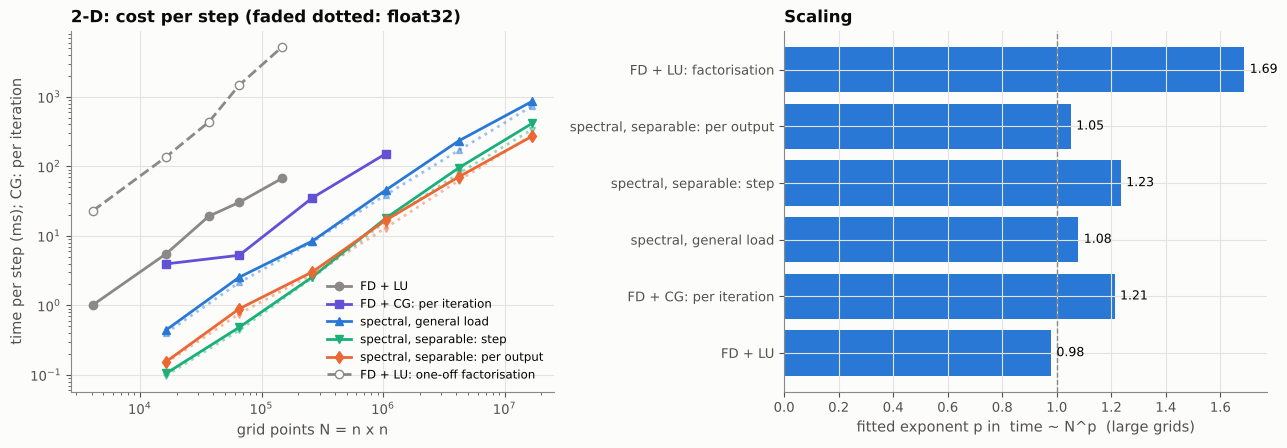

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
style = {"FD + LU": (ps.MUTED, "o-"), "FD + CG: per iteration": (ps.ACCENT, "s-"),
         "spectral, general load": (ps.VISCO, "^-"), "spectral, separable: step": (ps.ISO, "v-"),
         "spectral, separable: per output": (ps.ELASTIC, "d-")}
fits = {}
for m, (col, mk) in style.items():
    d = t2d[t2d.method == m]
    ax[0].loglog(d.N, d.step_s * 1e3, mk, color=col, label=m, ms=6)
    d32 = t2d[t2d.method == m + ", float32"]
    if len(d32):
        ax[0].loglog(d32.N, d32.step_s * 1e3, mk[0] + ":", color=col, alpha=0.45, ms=4)
    big = d[d.N >= 256**2] if len(d[d.N >= 256**2]) >= 2 else d
    fits[m] = np.polyfit(np.log(big.N), np.log(big.step_s), 1)
d = t2d[t2d.method == "FD + LU"]
ax[0].loglog(d.N, d.setup_s * 1e3, "o--", color=ps.MUTED, mfc="white", label="FD + LU: one-off factorisation")
fits["FD + LU: factorisation"] = np.polyfit(np.log(d.N[d.N >= 128**2]), np.log(d.setup_s[d.N >= 128**2]), 1)
ax[0].set_xlabel("grid points N = n x n"); ax[0].set_ylabel("time per step (ms); CG: per iteration")
ax[0].set_title("2-D: cost per step (faded dotted: float32)"); ax[0].legend(fontsize=8.5)
expo = pd.Series({k: v[0] for k, v in fits.items()})
ax[1].barh(expo.index, expo.values, color=ps.VISCO); ax[1].axvline(1, color=ps.MUTED, ls="--", lw=1)
ax[1].set_xlabel("fitted exponent p in  time ~ N^p  (large grids)"); ax[1].set_title("Scaling")
for i, v in enumerate(expo.values):
    ax[1].text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9)
fig.tight_layout(); plt.show()

### 4.4 Don't take steps you don't need

The spectral solver integrates each mode *exactly* for loads that vary linearly between the given times. So a fill–hold–drain history needs steps only at its 4 corners plus the output times, rather than hundreds of small steps. The two runs below produce the same answer to round-off.

In [25]:
n = 512; Q = circ(n); p = SpectralPlate(n, n, dx, shelf)
tf, th, tdr = 10 * DAY, 15 * DAY, 0.25 * DAY
hist = lambda s_: fill_hold_drain(s_, tf, th, tdr)
outs = np.array([10, 25, 25.25, 35]) * DAY

# naive: 1000 uniform steps (plus the output times), storing only the outputs
t_naive = np.unique(np.r_[np.linspace(0, 35 * DAY, 1001), outs, tf + th, tf + th + tdr])
st_naive = [int(np.flatnonzero(t_naive == o)[0]) for o in outs]
t_exact = np.unique(np.r_[0, tf, tf + th, tf + th + tdr, outs])
st_exact = [int(np.flatnonzero(t_exact == o)[0]) for o in outs]
t0 = time.perf_counter(); a_ = p.run(t_naive, (Q, hist), store=st_naive).w; tn = time.perf_counter() - t0
t0 = time.perf_counter(); b_ = p.run(t_exact, (Q, hist), store=st_exact).w; te_ = time.perf_counter() - t0
print(f"{n}x{n}: {len(t_naive)-1} steps {tn:.2f} s   vs   {len(t_exact)-1} steps {te_:.3f} s   "
      f"(max difference {np.abs(a_ - b_).max() / np.abs(a_).max():.1e} of the deflection)")

512x512: 1003 steps 5.14 s   vs   4 steps 0.181 s   (max difference 9.0e-16 of the deflection)


### 4.5 Many scenarios at once

Studies like BFRN need the response to *many* loads: lakes in different places, or many meltwater-redistribution maps. There are two shortcuts:

* **Linearity and superposition.** On a uniform shelf the response is translation-invariant. The response to one unit lake (a Green's function) can be convolved with any map of lakes, and that convolution is exactly what the FFT solver does.
* **Batching.** Stack the loads into one array and let a single multi-threaded FFT call transform them all.

Batching pays off for many *small* grids, where per-call overhead dominates. For large grids each FFT is already multi-threaded, so batching gains little.

In [26]:
import scipy.fft as sfft
rng = np.random.default_rng(0)
for n, nb in [(128, 512), (512, 32)]:
    xg_ = (np.arange(n) - n/2) * dx; X_, Y_ = np.meshgrid(xg_, xg_)
    loads = np.stack([shelf.lake_load(parabolic_lake(np.hypot(X_ - cx, Y_ - cy), 0, 1500, 4))
                      for cx, cy in rng.uniform(-2e3, 2e3, size=(nb, 2))])
    p = SpectralPlate(n, n, dx, shelf)
    one_by_one = best_time(lambda: [p.elastic(L) for L in loads], 2)
    batched = best_time(lambda: sfft.irfft2(sfft.rfft2(loads, workers=-1) / p.A, s=(n, n), workers=-1), 2)
    print(f"{nb:4d} elastic solves on {n}x{n}: one by one {one_by_one*1e3/nb:6.2f} ms each, "
          f"batched {batched*1e3/nb:6.2f} ms each  (x{one_by_one/batched:.1f})")

 512 elastic solves on 128x128: one by one   0.25 ms each, batched   0.15 ms each  (x1.6)


  32 elastic solves on 512x512: one by one   3.11 ms each, batched   6.24 ms each  (x0.5)


### 4.6 Run-time estimates

The fitted power laws from §4.3 give a quick estimator for this machine. It covers the 2-D methods; for the 1-D model, use the table in §4.2, where the time per step is roughly proportional to $N$. Conjugate gradients are costed as the per-iteration fit times the range of iteration counts seen in §4.3. That range is 2 to 27: the count falls when the lake is far from the clamped edges, where the preconditioner and the true operator differ, and it also depends on the time step. The finite-difference methods need $\Delta t \lesssim \tau/10$ (200 steps here is about 50 days), while the exact spectral method needs only the corners of the load history.

In [27]:
CG_ITERS = (int(t2d.cg_iterations.min()), int(t2d.cg_iterations.max()))   # range seen in 4.3
def t_of(method, N):
    p_, c_ = fits[method]
    return float(np.exp(c_) * N ** p_)

def estimate(nx, ny, n_steps, n_outputs, method):
    N = nx * ny
    if method == "FD + LU":
        return t_of("FD + LU: factorisation", N) + n_steps * t_of("FD + LU", N)
    if method == "FD + CG":   # (best, worst) for the range of iteration counts seen
        return tuple(n_steps * it * t_of("FD + CG: per iteration", N) for it in CG_ITERS)
    if method == "spectral, general load":
        return n_steps * t_of("spectral, general load", N)
    if method == "spectral, separable":
        return n_steps * t_of("spectral, separable: step", N) + n_outputs * t_of("spectral, separable: per output", N)

def fmt(s):
    if isinstance(s, tuple):
        return " to ".join(fmt(v) for v in s)
    return f"{s:.2g} s" if s < 120 else (f"{s/60:.2g} min" if s < 7200 else f"{s/3600:.2g} h")

cases = [  # name, nx, ny, steps, outputs
    ("single lake, 25 km square at 50 m", 512, 512, 200, 20),
    ("Nivlisen-size window, 33 km at 32 m", 1024, 1024, 200, 20),
    ("100 km x 100 km at 50 m", 2048, 2048, 200, 20),
    ("Larsen C-size, ~50 000 km^2 at 100 m", 2304, 2304, 200, 20),
    ("exact spectral: 6 steps, 4 outputs, 100 km at 50 m", 2048, 2048, 6, 4),
]
rows = []
for name, nx_, ny_, ns_, no_ in cases:
    row = dict(case=name, grid=f"{nx_} x {ny_}", steps=ns_)
    for m in ["FD + LU", "FD + CG", "spectral, general load", "spectral, separable"]:
        exact_only = name.startswith("exact")
        row[m] = "n/a" if (exact_only and m.startswith("FD")) else fmt(estimate(nx_, ny_, ns_, no_, m))
    rows.append(row)
pd.DataFrame(rows).set_index("case")

,grid,steps,FD + LU,FD + CG,"spectral, general load","spectral, separable"
case,,,,,,
"single lake, 25 km square at 50 m",512 x 512,200,37 s,12 s to 2.7 min,2 s,0.63 s
"Nivlisen-size window, 33 km at 32 m",1024 x 1024,200,3.9 min,65 s to 15 min,9.1 s,3.4 s
100 km x 100 km at 50 m,2048 x 2048,200,31 min,5.8 min to 79 min,41 s,18 s
"Larsen C-size, ~50 000 km^2 at 100 m",2304 x 2304,200,45 min,7.8 min to 1e+02 min,52 s,25 s
"exact spectral: 6 steps, 4 outputs, 100 km at 50 m",2048 x 2048,6,n/a,n/a,1.2 s,0.78 s


These are extrapolations, so treat the large-grid FD + LU numbers with particular caution. Sparse LU memory grows faster than its run time, and on most laptops it runs out of memory well before 2000 × 2000.

### 4.7 Recommendations

| problem | use | why |
|---|---|---|
| 1-D transects, one-off runs | `ViscoelasticBeam.run` | simple; ~1 s for thousands of nodes × steps |
| 1-D, many runs or very long histories | `fast_beam.run_numba` | 2–4× faster per step, same answers; `run_banded` (no Numba) is *not* faster |
| 2-D lakes on a large, uniform floating shelf | `SpectralPlate` with a separable load and steps only at load corners and outputs | exact in time; cost ≈ a few FFTs per output; float32 roughly doubles the speed |
| 2-D with grounding lines or other fixed boundaries | `FDPlate(fixed=mask)` with LU up to ~400 × 400, or coarser grids ($\Delta x \lesssim \ell/5$ is enough) | handles any grounded geometry |
| large 2-D rectangles with clamped edges | `FDPlate(solver="cg")` | no factorisation, $O(N\log N)$ per iteration, little memory |
| many lake scenarios | superpose or batch FFTs (§4.5) | one transform for many loads |

Further speed-ups not tried here:

* **GPU.** The spectral solver is a handful of FFTs and element-wise operations, so swapping NumPy and SciPy FFTs for CuPy would typically speed it up by an order of magnitude or more on a GPU.
* **Pre-factorised multigrid or a fast-transform preconditioner** for the masked finite-difference problem. This would scale better than sparse LU on large grounded domains.
* **Coarser grids.** Accuracy needs only $\Delta x \lesssim \ell/5$ to $\ell/10$ (§2.8). With $\ell \approx 600$ m, a 60–120 m grid is plenty for flexure even when the lake map is finer. Block-average the load, as in §3.6.